# EDA + preprocessing

In [1]:
import pandas as pd
import numpy as np
from scipy.spatial.distance import cdist

DATA_PATH = "./"

train = pd.read_csv(DATA_PATH + "train.csv")
features = pd.read_csv(DATA_PATH + "features.csv")
stores = pd.read_csv(DATA_PATH + "stores.csv")

In [2]:
train.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


In [3]:
features.head()

,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,2010-02-05,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,2010-02-12,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,2010-02-19,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,2010-02-26,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,2010-03-05,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False


In [4]:
stores.head()

,Store,Type,Size
0,1,A,151315
1,2,A,202307
2,3,B,37392
3,4,A,205863
4,5,B,34875


Check basic structure

In [5]:

for name, df in {"train": train, "features": features, "stores": stores}.items():
    print(f"\n{name.upper()}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head())
    display(df.dtypes)


TRAIN
Shape: (421570, 5)
Columns: ['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday']


,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


Store             int64
Dept              int64
Date             object
Weekly_Sales    float64
IsHoliday          bool
dtype: object


FEATURES
Shape: (8190, 12)
Columns: ['Store', 'Date', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'IsHoliday']


,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,2010-02-05,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,2010-02-12,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,2010-02-19,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,2010-02-26,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,2010-03-05,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False


Store             int64
Date             object
Temperature     float64
Fuel_Price      float64
MarkDown1       float64
MarkDown2       float64
MarkDown3       float64
MarkDown4       float64
MarkDown5       float64
CPI             float64
Unemployment    float64
IsHoliday          bool
dtype: object


STORES
Shape: (45, 3)
Columns: ['Store', 'Type', 'Size']


,Store,Type,Size
0,1,A,151315
1,2,A,202307
2,3,B,37392
3,4,A,205863
4,5,B,34875


Store     int64
Type     object
Size      int64
dtype: object

Check data coverage

In [6]:

print("Train date range:", train["Date"].min(), "to", train["Date"].max())
print("Features date range:", features["Date"].min(), "to", features["Date"].max())

print("\nNumber of stores:", train["Store"].nunique())
print("Number of departments:", train["Dept"].nunique())
print("Number of Store–Dept combinations:",
      train[["Store", "Dept"]].drop_duplicates().shape[0])

print("\nRows per Store–Dept combination:")
display(
    train.groupby(["Store", "Dept"]).size().describe()
)

Train date range: 2010-02-05 to 2012-10-26
Features date range: 2010-02-05 to 2013-07-26

Number of stores: 45
Number of departments: 81
Number of Store–Dept combinations: 3331

Rows per Store–Dept combination:


count    3331.000000
mean      126.559592
std        40.212763
min         1.000000
25%       143.000000
50%       143.000000
75%       143.000000
max       143.000000
dtype: float64

BusPaS needs descriptive variables and target variables, not a sales-forecasting feature matrix. Markdown variables are omitted because the provided BusPaS setup does not use them and they contain extensive missingness.

In [7]:
features = features[["Store", "Date", "IsHoliday", "Temperature", "Fuel_Price", "CPI", "Unemployment"]].copy()

Check missing values -> no missing values

In [8]:

print("Missing values in train:")
display(train.isna().sum().sort_values(ascending=False))

print("\nMissing values in features:")
display(features.isna().sum().sort_values(ascending=False))

print("\nMissing values in stores:")
display(stores.isna().sum().sort_values(ascending=False))

Missing values in train:


Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
dtype: int64


Missing values in features:


CPI             585
Unemployment    585
Store             0
Date              0
IsHoliday         0
Temperature       0
Fuel_Price        0
dtype: int64


Missing values in stores:


Store    0
Type     0
Size     0
dtype: int64

Checking duplicates

In [9]:
train["Date"] = pd.to_datetime(train["Date"], errors="coerce")
features["Date"] = pd.to_datetime(features["Date"], errors="coerce")

print("Missing dates in train:", train["Date"].isna().sum())
print("Missing dates in features:", features["Date"].isna().sum())

print("Duplicate Store–Dept–Date rows in train:",
      train.duplicated(["Store", "Dept", "Date"]).sum())

print("Duplicate Store–Date rows in features:",
      features.duplicated(["Store", "Date"]).sum())

print("Duplicate Store rows in stores:",
      stores.duplicated(["Store"]).sum())

Missing dates in train: 0
Missing dates in features: 0
Duplicate Store–Dept–Date rows in train: 0
Duplicate Store–Date rows in features: 0
Duplicate Store rows in stores: 0


We remove null values and negative values because negative values usually reflect refund and can distort a store's average sales

In [10]:
train_clean = train.dropna(subset=["Store", "Dept", "Date", "Weekly_Sales"]).copy()

negative_sales = (train_clean["Weekly_Sales"] < 0).sum()
print("Negative Weekly_Sales rows:", negative_sales)

# Treat negative values as returns/refunds, not normal weekly demand.
train_clean = train_clean[train_clean["Weekly_Sales"] >= 0].copy()

Negative Weekly_Sales rows: 1285


Check sales distribution

The graphs show that weekly_sales is strongly right skewed, and in the boxplot there are many outlier values, but we don't remove these values because in retail data is high values might be meaningful since large stores can genuinely sell much more than others

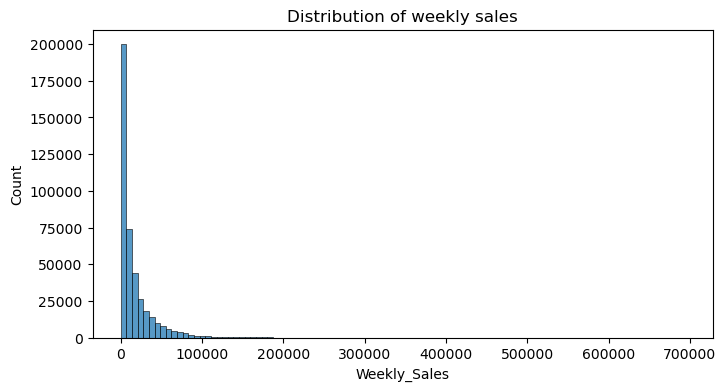

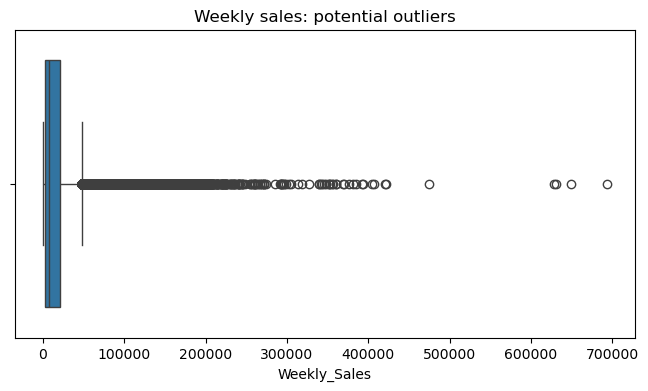

In [11]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.histplot(train_clean["Weekly_Sales"], bins=100)
plt.title("Distribution of weekly sales")
plt.show()

plt.figure(figsize=(8, 4))
sns.boxplot(x=train_clean["Weekly_Sales"])
plt.title("Weekly sales: potential outliers")
plt.show()

The highest weekly sales values are mainly generated by Department 72 across multiple stores. Since these Store–Department combinations also have high average and total sales over all 143 weeks, the extreme values appear to be genuine retail differences rather than isolated data errors. Therefore, they are retained.

In [12]:
# Check which Store–Department combinations produce the highest sales
display(
    train_clean.groupby(["Store", "Dept"])["Weekly_Sales"]
    .agg(["mean", "max", "sum", "count"])
    .sort_values("max", ascending=False)
    .head(10)
)

,,mean,max,sum,count
Store,Dept,,,,
10,72,142733.752168,693099.36,20410926.56,143
35,72,88331.808881,649770.18,12631448.67,143
14,72,94140.832867,474330.10,13462139.10,143
20,72,91989.863217,422306.25,13154550.44,143
27,72,68527.765944,420586.57,9799470.53,143
10,7,58964.715664,406988.63,8431954.34,143
22,72,66645.669021,393705.20,9530330.67,143
4,72,101244.450839,385051.04,14477956.47,143
23,72,76844.022727,369830.98,10988695.25,143


We can also inspect the difference between holiday and non holiday sales. 

The results that we get say that weekly sales are higher during holiday weeks: both the mean and median sales increase compared with non-holiday weeks. Holiday sales also show greater variability, suggesting that holidays affect stores and departments differently. 

In [13]:

holiday_sales = (
    train_clean.groupby("IsHoliday")["Weekly_Sales"]
    .agg(["count", "mean", "median", "std"])
)

display(holiday_sales)

,count,mean,median,std
IsHoliday,,,,
False,390722,15949.958317,7636.08,22347.258698
True,29563,17092.566220,7997.86,27249.206776


We check if every store-department combination has data for each week

The dataset contains 143 weekly dates. Of the 3,323 Store–Department combinations, 695 do not have sales observations for every week. Because BUSPaS compares sales trajectories, only combinations with complete 143-week time series are retained to ensure fair and consistent comparison.

In [14]:
expected_weeks = train_clean["Date"].nunique()

series_lengths = train_clean.groupby(["Store", "Dept"])["Date"].nunique()

print("Expected number of weeks:", expected_weeks)
print("Store–Dept series lengths:")
display(series_lengths.describe())

print("Incomplete Store–Dept series:",
      (series_lengths < expected_weeks).sum())

Expected number of weeks: 143
Store–Dept series lengths:


count    3323.000000
mean      126.477580
std        40.302689
min         1.000000
25%       143.000000
50%       143.000000
75%       143.000000
max       143.000000
Name: Date, dtype: float64

Incomplete Store–Dept series: 695


In [15]:
# One row = one Store–Department combination
# One column = one weekly date
sales_matrix_all = train_clean.pivot(
    index=["Store", "Dept"],
    columns="Date",
    values="Weekly_Sales"
)

# Count the weeks with no sales record for each Store–Department combination
missing_weeks = sales_matrix_all.isna().sum(axis=1)

missing_by_store_dept = (
    missing_weeks
    .reset_index(name="missing_weeks")
    .sort_values("missing_weeks", ascending=False)
)

print("\nNumber of Store–Department combinations for each amount of missing weeks:")
display(missing_by_store_dept["missing_weeks"].value_counts().sort_index())

print("\nComplete trajectories:", (missing_weeks == 0).sum())
print("Incomplete trajectories:", (missing_weeks > 0).sum())


Number of Store–Department combinations for each amount of missing weeks:


missing_weeks
0      2628
1        39
2        19
3        12
4         6
       ... 
138      15
139      27
140      15
141      30
142      40
Name: count, Length: 134, dtype: int64


Complete trajectories: 2628
Incomplete trajectories: 695


In [16]:
# Group Store–Department combinations by amount of missing data

missing_groups = pd.cut(
    missing_by_store_dept["missing_weeks"],
    bins=[-1, 0, 7, 15, 25, 50, 142],
    labels=[
        "0 missing (complete)",
        "1–7 missing",
        "8–15 missing",
        "15–25 missing",
        "26–50 missing",
        "51–142 missing"
    ]
)

display(
    missing_groups
    .value_counts()
    .sort_index()
    .rename("number_of_Store_Dept_combinations")
    .to_frame()
)

,number_of_Store_Dept_combinations
missing_weeks,
0 missing (complete),2628
1–7 missing,89
8–15 missing,43
15–25 missing,44
26–50 missing,84
51–142 missing,435


In [17]:
# Check whether short gaps occur inside the trajectory
# or at the beginning/end, where interpolation is not appropriate.

short_gap_matrix = sales_matrix_all.loc[
    missing_weeks.between(1, 15)
]

def gap_location(row):
    observed = row.notna().to_numpy()

    if not observed[0] or not observed[-1]:
        return "missing at start or end"
    return "internal gap only"

short_gap_locations = short_gap_matrix.apply(gap_location, axis=1)

display(
    short_gap_locations
    .value_counts()
    .rename("number_of_Store_Dept_combinations")
    .to_frame()
)

,number_of_Store_Dept_combinations
internal gap only,113
missing at start or end,19


In [18]:
# Keep only Store–Department combinations with internal gaps only
internal_gap_matrix = short_gap_matrix.loc[
    short_gap_locations[
        short_gap_locations == "internal gap only"
    ].index
]

# Create one row for every consecutive internal missing-data gap
gap_details = []

for (store, dept), row in internal_gap_matrix.iterrows():
    is_missing = row.isna()

    # Give each consecutive run of missing/non-missing values a group number
    run_id = is_missing.ne(is_missing.shift()).cumsum()

    # Keep only groups that are missing
    for _, gap in row[is_missing].groupby(run_id[is_missing]):
        gap_details.append({
            "Store": store,
            "Dept": dept,
            "gap_start": gap.index.min(),
            "gap_end": gap.index.max(),
            "gap_length_weeks": len(gap)
        })

gap_details = pd.DataFrame(gap_details)

display(gap_details.sort_values("gap_length_weeks", ascending=False).head(20))

print("Number of Store–Department combinations analysed:",
      internal_gap_matrix.shape[0])

print("\nDistribution of consecutive internal gap lengths:")
display(
    gap_details["gap_length_weeks"]
    .value_counts()
    .sort_index()
    .rename("number_of_gaps")
    .to_frame()
)

,Store,Dept,gap_start,gap_end,gap_length_weeks
378,44,42,2012-03-16,2012-05-04,8
115,18,83,2011-08-19,2011-09-30,7
116,18,93,2011-08-19,2011-09-30,7
117,18,97,2011-08-26,2011-09-30,6
201,27,58,2012-01-06,2012-02-10,6
186,27,18,2010-04-30,2010-05-28,5
48,7,80,2010-04-09,2010-05-07,5
130,19,54,2012-09-28,2012-10-19,4
30,3,97,2011-02-11,2011-02-25,3
276,35,59,2012-07-06,2012-07-20,3


Number of Store–Department combinations analysed: 113

Distribution of consecutive internal gap lengths:


,number_of_gaps
gap_length_weeks,
1,319
2,50
3,17
4,1
5,2
6,2
7,2
8,1


Number of retained Store–Department combinations: 105


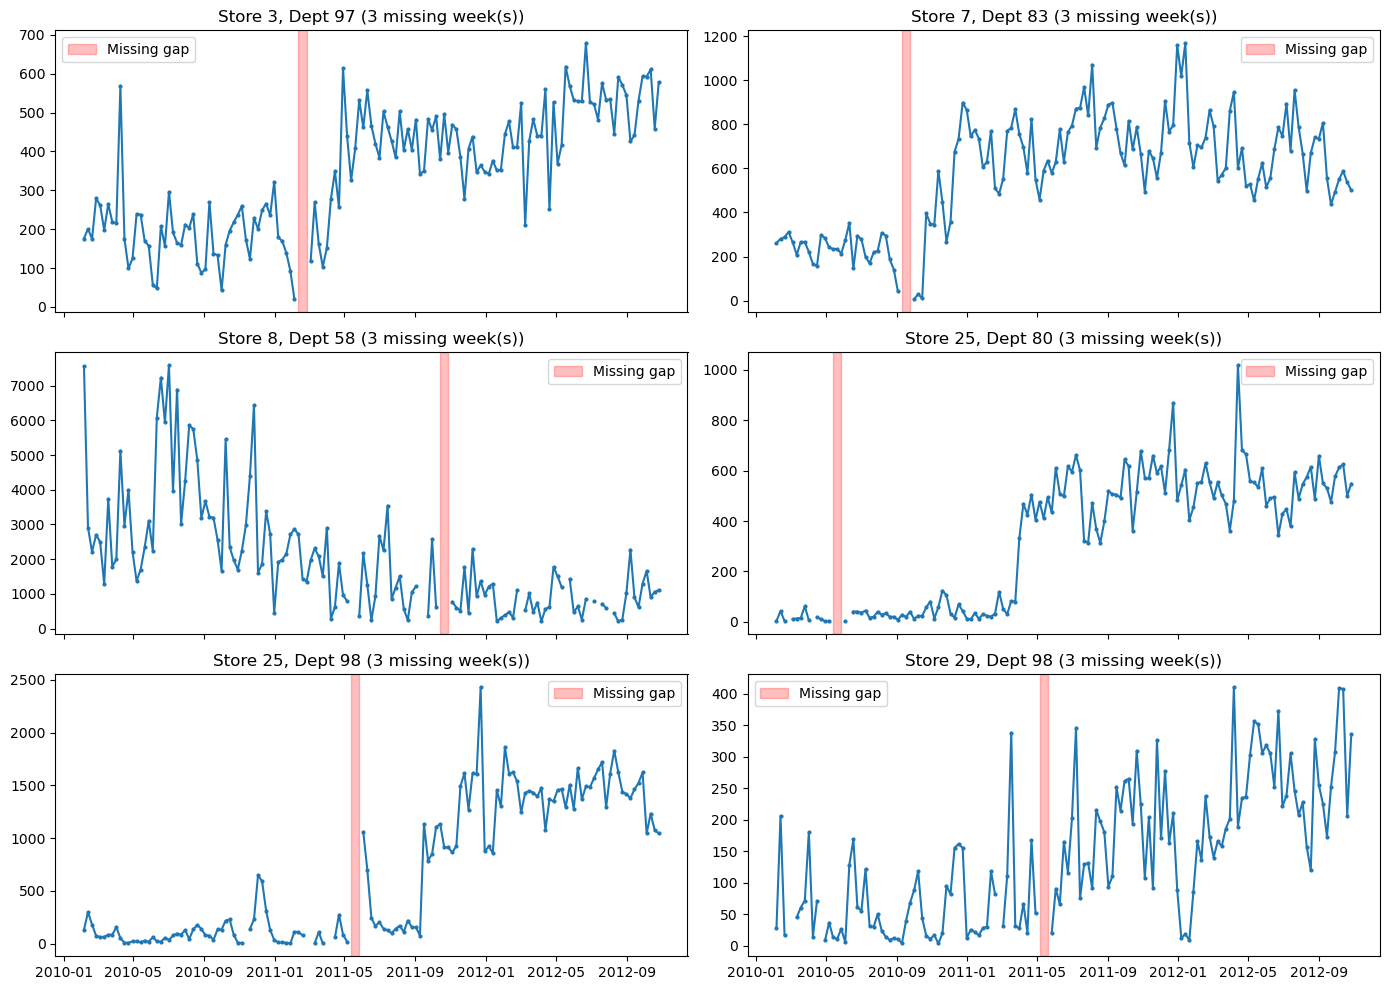

In [19]:
# `gap_details` already contains only:
# - Store–Department combinations with <= 15 missing weeks
# - internal-gap-only combinations

# Find the longest consecutive gap for each Store–Department combination
retained_pairs = (
    gap_details
    .groupby(["Store", "Dept"])["gap_length_weeks"]
    .max()
)

# Keep only combinations where the longest gap is at most 3 weeks
retained_pairs = retained_pairs[
    retained_pairs <= 3
].index

# Keep gap records only for retained combinations
retained_gap_details = (
    gap_details
    .set_index(["Store", "Dept"])
    .loc[retained_pairs]
    .reset_index()
)

print("Number of retained Store–Department combinations:",
      len(retained_pairs))

# Plot six retained trajectories with the longest gaps
examples = retained_gap_details.nlargest(6, "gap_length_weeks")

fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharex=True)
axes = axes.flatten()

for ax, (_, gap) in zip(axes, examples.iterrows()):
    trajectory = sales_matrix_all.loc[(gap["Store"], gap["Dept"])]

    ax.plot(trajectory.index, trajectory.values, marker="o", markersize=2)
    ax.axvspan(
        gap["gap_start"],
        gap["gap_end"],
        color="red",
        alpha=0.25,
        label="Missing gap"
    )
    ax.set_title(
        f"Store {gap['Store']}, Dept {gap['Dept']} "
        f"({gap['gap_length_weeks']} missing week(s))"
    )
    ax.legend()

# Hide unused plots if there are fewer than six examples
for ax in axes[len(examples):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

Using the above analysis we try to see how to deal with store-dept combinations that have missing weeks data. We firstly look at the quantity of weeks missingfor each combination, then we notice that most of the combinations have more than 15 out of 143 missing, and if we try to take the mean of too many gaps might cause too much false data, so we only keep combinations with less than or equal to 15 weeks missing. Then out of these 89+43 combinations with less than 15 weeks missing, we see if data is missing internally or at the start or end. it turns out that 113 combinations have internal gap only and 19 have missing at start or end. Since it is easier to assume data distribution if we have data before and after the missing point, we keep only the data with internal gap only. Then we check how consecutive is the internal missing gap. We see that most of the missing gap is of length 1,2 or 3, so we can keep the ones that have at most 3 consecutive weeks gap. To deal with these remaining combinations, we use linear interpolation.

In [20]:
# Keep complete trajectories and eligible incomplete trajectories,
# then linearly interpolate their short internal gaps.

max_total_missing_weeks = 15
max_consecutive_gap_weeks = 3

# One row = Store–Department combination; one column = weekly date
all_dates = pd.Index(sorted(train_clean["Date"].unique()), name="Date")

sales_matrix_all = (
    train_clean
    .pivot(index=["Store", "Dept"], columns="Date", values="Weekly_Sales")
    .reindex(columns=all_dates)
)

# Count total missing weeks per Store–Department combination
missing_weeks = sales_matrix_all.isna().sum(axis=1)

# 1. Keep all complete trajectories
complete_index = sales_matrix_all.index[missing_weeks == 0]

# 2. Consider incomplete trajectories with at most 15 missing weeks
candidate_matrix = sales_matrix_all.loc[
    missing_weeks.between(1, max_total_missing_weeks)
]

# 3. Keep only trajectories with missing values inside the observed period
def gap_location(row):
    observed = row.notna().to_numpy()

    if not observed[0] or not observed[-1]:
        return "missing at start or end"
    return "internal gap only"

candidate_gap_locations = candidate_matrix.apply(gap_location, axis=1)

internal_gap_matrix = candidate_matrix.loc[
    candidate_gap_locations[
        candidate_gap_locations == "internal gap only"
    ].index
]

# 4. Find the longest consecutive missing gap in each trajectory
gap_details = []

for (store, dept), row in internal_gap_matrix.iterrows():
    is_missing = row.isna()
    run_id = is_missing.ne(is_missing.shift()).cumsum()

    for _, gap in row[is_missing].groupby(run_id[is_missing]):
        gap_details.append({
            "Store": store,
            "Dept": dept,
            "gap_length_weeks": len(gap)
        })

gap_details = pd.DataFrame(gap_details)

longest_gap = (
    gap_details
    .groupby(["Store", "Dept"])["gap_length_weeks"]
    .max()
)

# 5. Retain only trajectories with no gap longer than three weeks
retained_internal_index = longest_gap[
    longest_gap <= max_consecutive_gap_weeks
].index

retained_index = complete_index.append(retained_internal_index).sort_values()

# 6. Interpolate the remaining short internal gaps
sales_matrix_retained = sales_matrix_all.loc[retained_index].interpolate(
    axis=1,
    method="linear",
    limit=max_consecutive_gap_weeks,
    limit_area="inside"
)

assert sales_matrix_retained.isna().sum().sum() == 0

# Convert the completed trajectory matrix back to long format
train_complete = (
    sales_matrix_retained
    .rename_axis(index=["Store", "Dept"], columns="Date")
    .stack()
    .rename("Weekly_Sales")
    .reset_index()
)

# Restore IsHoliday for the newly interpolated Store–Department–Date rows
holiday_lookup = (
    train_clean[["Date", "IsHoliday"]]
    .drop_duplicates("Date")
)

train_complete = train_complete.merge(
    holiday_lookup,
    on="Date",
    how="left",
    validate="many_to_one"
)

print("Rows before:", len(train_clean))
print("Rows after:", len(train_complete))
print("Final Store–Department combinations:",
      train_complete[["Store", "Dept"]].drop_duplicates().shape[0])
print("Remaining missing Weekly_Sales values:",
      train_complete["Weekly_Sales"].isna().sum())

Rows before: 420285
Rows after: 390819
Final Store–Department combinations: 2733
Remaining missing Weekly_Sales values: 0


We merge the three datasets into one

In [21]:
walmart_data = (
    train_complete
    .merge(features, on=["Store", "Date", "IsHoliday"], how="left")
    .merge(stores, on="Store", how="left")
)

print("Merged shape:", walmart_data.shape)
print("Rows lost compared with train_complete:", len(train_complete) - len(walmart_data))

print("\nMissing values after merging:")
display(walmart_data.isna().sum().sort_values(ascending=False))

Merged shape: (390819, 11)
Rows lost compared with train_complete: 0

Missing values after merging:


Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
Type            0
Size            0
dtype: int64

We try plotting the weekly sales pattern for store 1 department 1

Weekly sales are generally stable at around 15,000–25,000, but there are repeated sharp peaks reaching approximately 50,000–58,000. These recurring peaks suggest seasonal or holiday-related demand. This illustrates the type of sales behaviour that BUSPaS can compare across Store–Department combinations to identify exceptional patterns.

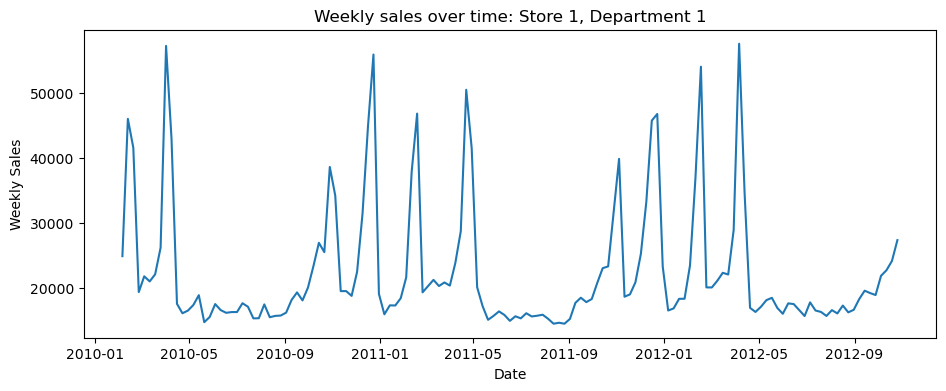

In [22]:

example = walmart_data[(walmart_data["Store"] == 1) & (walmart_data["Dept"] == 1)].sort_values("Date")

plt.figure(figsize=(11, 4))
plt.plot(example["Date"], example["Weekly_Sales"])
plt.title("Weekly sales over time: Store 1, Department 1")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.show()

We also inspect the association between weekly sales for each store, tempeature, fuel price, CPI and unemployment.

The visualisations show weak overall linear associations between total weekly sales and temperature, fuel price, CPI, and unemployment. Fuel price has virtually no relationship with sales, while temperature, CPI, and unemployment show only slight negative trends. Therefore, these variables do not appear to strongly explain overall sales levels on their own. However, they may still affect particular Store–Department subgroups differently, which BUSPaS can investigate through subgroup-specific response measures.

In [23]:
# One row per Store–Date: total sales and that week's external conditions
store_week = (
    walmart_data
    .groupby(["Store", "Date"], as_index=False)
    .agg(
        Total_Weekly_Sales=("Weekly_Sales", "sum"),
        Temperature=("Temperature", "first"),
        Fuel_Price=("Fuel_Price", "first"),
        CPI=("CPI", "first"),
        Unemployment=("Unemployment", "first"),
        IsHoliday=("IsHoliday", "first")
    )
)

display(store_week.head())

,Store,Date,Total_Weekly_Sales,Temperature,Fuel_Price,CPI,Unemployment,IsHoliday
0,1,2010-02-05,1638038.80,42.31,2.572,211.096358,8.106,False
1,1,2010-02-12,1622641.36,38.51,2.548,211.242170,8.106,True
2,1,2010-02-19,1594777.63,39.93,2.514,211.289143,8.106,False
3,1,2010-02-26,1408776.00,46.63,2.561,211.319643,8.106,False
4,1,2010-03-05,1553286.80,46.50,2.625,211.350143,8.106,False


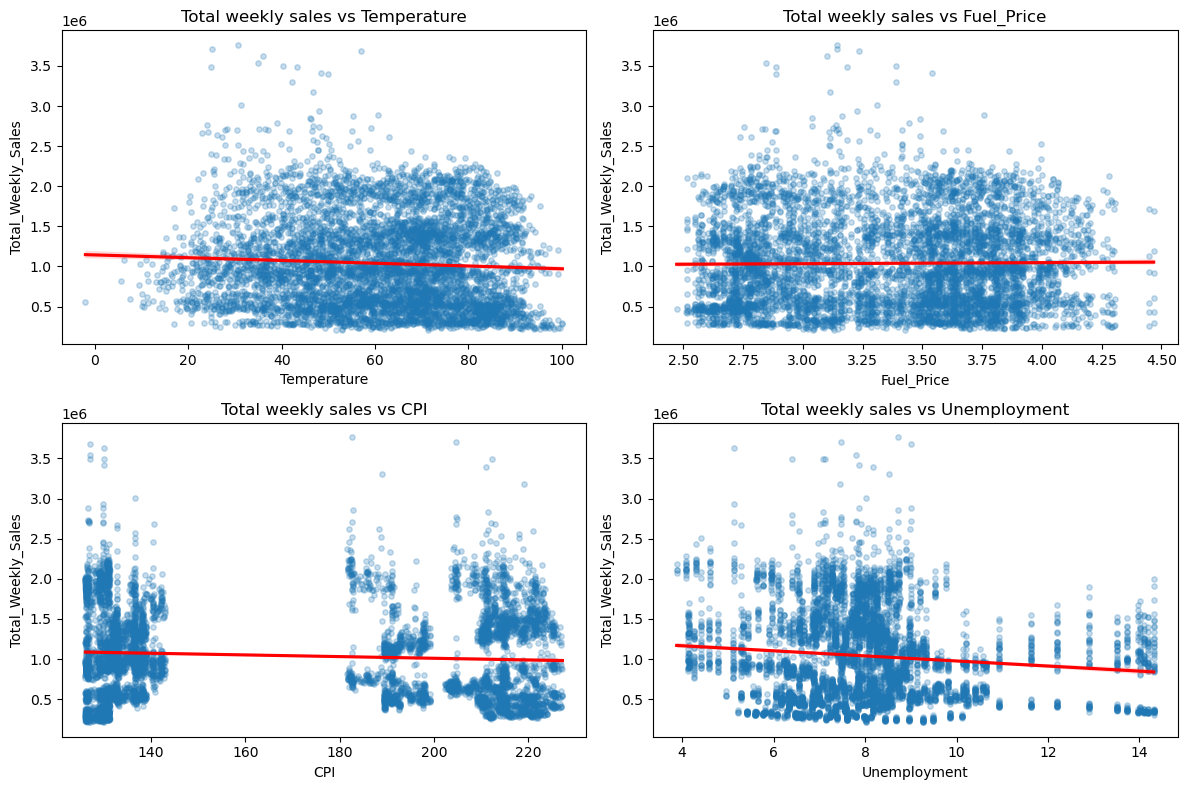

In [24]:
variables = ["Temperature", "Fuel_Price", "CPI", "Unemployment"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, variable in zip(axes.flat, variables):
    sns.regplot(
        data=store_week,
        x=variable,
        y="Total_Weekly_Sales",
        scatter_kws={"alpha": 0.25, "s": 15},
        line_kws={"color": "red"},
        ax=ax
    )
    ax.set_title(f"Total weekly sales vs {variable}")

plt.tight_layout()
plt.show()

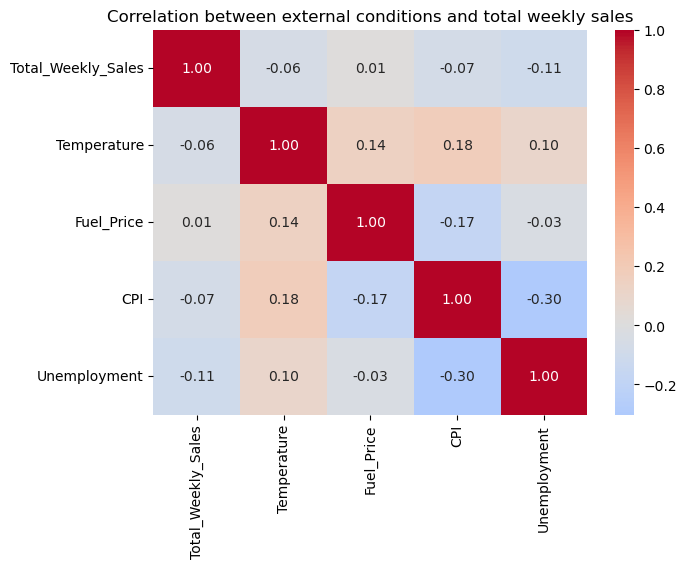

In [25]:
plt.figure(figsize=(7, 5))

correlation = store_week[
    ["Total_Weekly_Sales", "Temperature", "Fuel_Price", "CPI", "Unemployment"]
].corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation between external conditions and total weekly sales")
plt.show()

Next we inspect the relation between store-department combination weekly sales and the other variables. 

The boxplot below uses all 143 weekly observations for each Store–Department combination. For every combination, it calculates the correlation between its Weekly_Sales values and the corresponding weekly values of Temperature, Fuel_Price, CPI, and Unemployment. The plot summarizes these correlation values across all Store–Department combinations. Although the median correlations are close to zero, the wide spread shows that sales sensitivity differs substantially across combinations. Some pairs have strong positive or negative relationships, making these variables useful for deriving BUSPaS target measures.

In [26]:
variables = ["Temperature", "Fuel_Price", "CPI", "Unemployment"]

def sales_correlations(group):
    return pd.Series({
        variable: group["Weekly_Sales"].corr(group[variable])
        for variable in variables
    })

pair_correlations = (
    walmart_data
    .groupby(["Store", "Dept"])[["Weekly_Sales"] + variables]
    .apply(sales_correlations)
)

display(pair_correlations.head())

Temperature  Fuel_Price       CPI  Unemployment
Store Dept                                                 
1     1       -0.473860   -0.066396 -0.043533      0.103399
      2       -0.014821    0.034471  0.121627     -0.045789
      3        0.336490    0.027219  0.072986     -0.089588
      4        0.009820    0.031813  0.230685     -0.175366
      5       -0.511538   -0.128661 -0.019696      0.166538

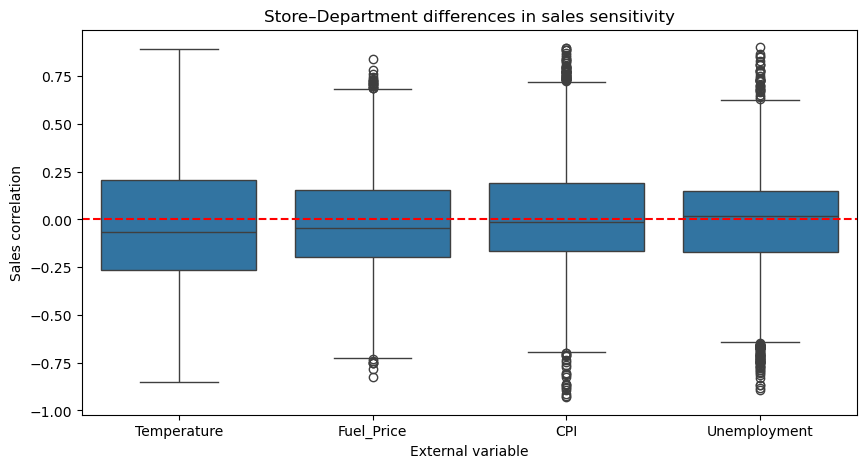

In [27]:
pair_correlations_long = pair_correlations.reset_index().melt(
    id_vars=["Store", "Dept"],
    value_vars=variables,
    var_name="External variable",
    value_name="Sales correlation"
)

plt.figure(figsize=(10, 5))
sns.boxplot(
    data=pair_correlations_long,
    x="External variable",
    y="Sales correlation"
)
plt.axhline(0, color="red", linestyle="--")
plt.title("Store–Department differences in sales sensitivity")
plt.show()

# Quality measure EDA

In [28]:
# One row = one Store–Department combination
# One column = one weekly date
# This is the target input needed for both quality-measure checks.

sales_matrix = (
    walmart_data
    .pivot(index=["Store", "Dept"], columns="Date", values="Weekly_Sales")
    .sort_index(axis=1)
)

print("Trajectory matrix shape:", sales_matrix.shape)
print("Missing values in trajectory matrix:", sales_matrix.isna().sum().sum())
print("Number of weekly dates:", sales_matrix.shape[1])

display(sales_matrix.iloc[:5, :5])

Trajectory matrix shape: (2733, 143)
Missing values in trajectory matrix: 0
Number of weekly dates: 143


Date        2010-02-05  2010-02-12  2010-02-19  2010-02-26  2010-03-05
Store Dept                                                            
1     1       24924.50    46039.49    41595.55    19403.54    21827.90
      2       50605.27    44682.74    47928.89    44292.87    48397.98
      3       13740.12    10887.84    11523.47    11135.17    12275.58
      4       39954.04    35351.21    36826.95    34660.16    38086.19
      5       32229.38    29620.81    26468.27    24101.89    23082.14

The analysis below tell us if buspas measure is suitable, to do this we see if there is enough distance between the different shapes because the measure relies on the distance between pairs.

The data are suitable for the BUSPaS clustering quality measure. The dataset contains 2,628 complete, non-constant Store–Department sales trajectories with a common length of 143 weeks. Raw Euclidean distances are strongly influenced by large differences in absolute sales level; therefore, applying the measure to raw sales would primarily identify high- or low-sales groups. After standardising each trajectory individually, pairwise distances retain substantial variation, demonstrating that the data contain distinguishable sales shapes. Hence, the standardised trajectories are appropriate input for the BUSPaS distance-based quality measure when the aim is to find exceptional long-term sales patterns.

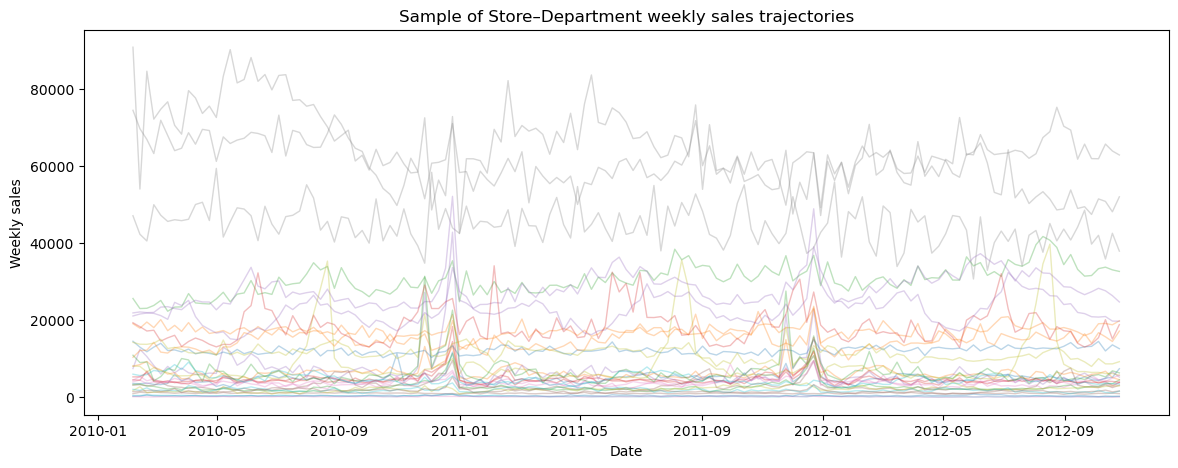

In [29]:
# Plot several Store–Department sales trajectories, rather than only one example

sample_trajectories = sales_matrix.sample(30, random_state=42)

plt.figure(figsize=(14, 5))

for _, trajectory in sample_trajectories.iterrows():
    plt.plot(
        sales_matrix.columns,
        trajectory.values,
        alpha=0.30,
        linewidth=1
    )

plt.title("Sample of Store–Department weekly sales trajectories")
plt.xlabel("Date")
plt.ylabel("Weekly sales")
plt.show()

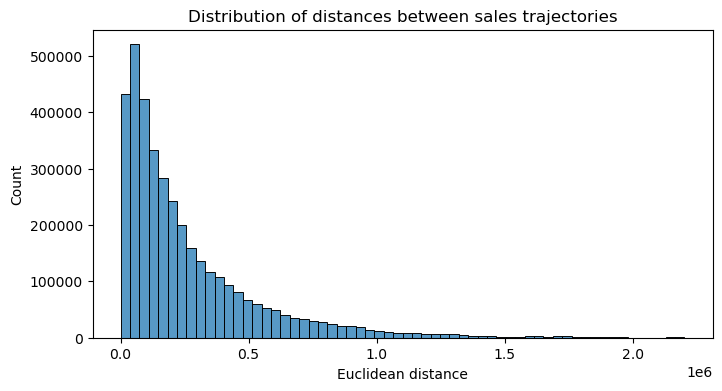

count    3.733278e+06
mean     2.643857e+05
std      2.868272e+05
min      1.709755e+02
25%      7.209151e+04
50%      1.668623e+05
75%      3.528388e+05
max      2.202198e+06
dtype: float64


In [30]:
# Examine how different trajectories are when Euclidean distance is used

from scipy.spatial.distance import pdist

raw_distances = pdist(sales_matrix.values, metric="euclidean")

plt.figure(figsize=(8, 4))
sns.histplot(raw_distances, bins=60)
plt.title("Distribution of distances between sales trajectories")
plt.xlabel("Euclidean distance")
plt.show()

print(pd.Series(raw_distances).describe())

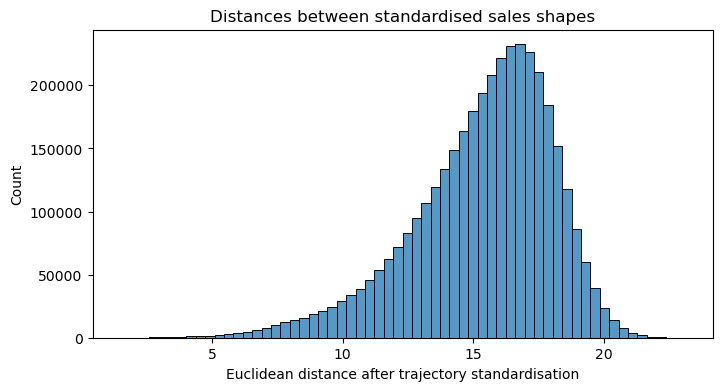

In [31]:
# Compare trajectory shapes after removing each trajectory's own sales level and scale.
# Do this only if your goal is "unusual shape over time".

sales_matrix_shape = sales_matrix.sub(sales_matrix.mean(axis=1), axis=0).div(
    sales_matrix.std(axis=1).replace(0, np.nan),
    axis=0
)

shape_distances = pdist(sales_matrix_shape.values, metric="euclidean")

plt.figure(figsize=(8, 4))
sns.histplot(shape_distances, bins=60)
plt.title("Distances between standardised sales shapes")
plt.xlabel("Euclidean distance after trajectory standardisation")
plt.show()

Next we see if RCS or rankbiserial correlation is suitable by analysing skewness of data. 

As shown earlier, the original weekly sales values are strongly right-skewed, with a small number of Store–Department combinations having exceptionally large sales. After standardising each Store–Department trajectory to remove its own average sales level and scale, the cross-sectional sales distributions at individual weeks remain asymmetric with long positive tails. Thus, standardisation supports shape-based comparison but does not make the target values normally distributed. Therefore, we use rank-biserial correlation rather than a mean and standard-error based score, because it compares subgroup and complement using ranks and is robust to skewed distributions and extreme values.


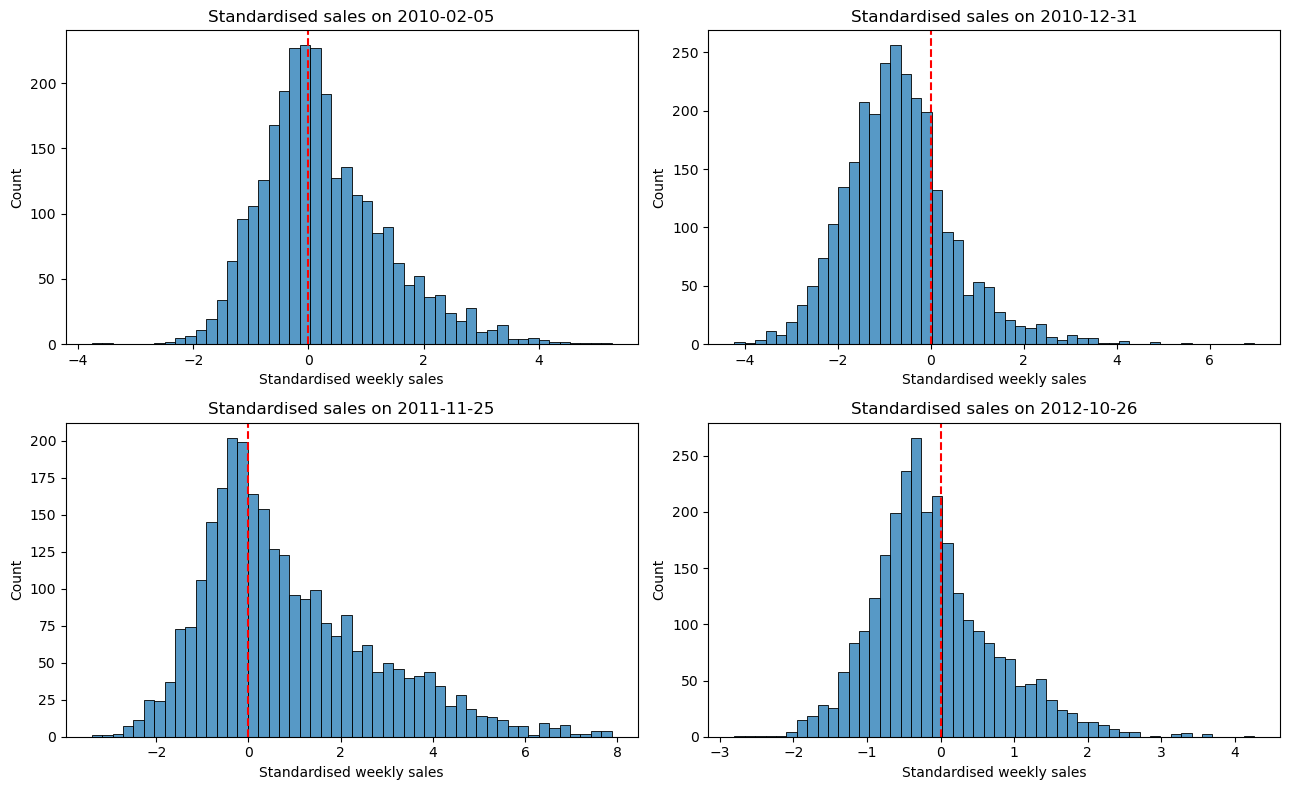

In [32]:
# Standardise each Store–Department sales trajectory across time
sales_matrix_standardised = sales_matrix.sub(
    sales_matrix.mean(axis=1), axis=0
).div(
    sales_matrix.std(axis=1), axis=0
)

# Plot standardised sales distributions for four weeks
chosen_dates = sales_matrix_standardised.columns[
    np.linspace(0, len(sales_matrix_standardised.columns) - 1, 4, dtype=int)
]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for ax, date in zip(axes.flat, chosen_dates):
    sns.histplot(sales_matrix_standardised[date], bins=50, ax=ax)
    ax.axvline(0, color="red", linestyle="--")
    ax.set_title(f"Standardised sales on {date.date()}")
    ax.set_xlabel("Standardised weekly sales")

plt.tight_layout()
plt.show()

# preprocessing - transform variables

Prepare the variables for your BUSPaS code

Using the BUSPaS algorithm, we want to identify Store–Department combinations with unusual sales shapes over time. To do this, each changing variable must be transformed into a fixed value per Store–Department if we want to include information about the other variables in the subgroup description.

An idea is to use the average values over all weeks for temperature, fuel price, CPI, and unemployment. These averages can be included as descriptive variables together with department, store type, and store size. BUSPaS can then identify subgroups such as stores with high average temperature or low average unemployment that have an unusual sales pattern over time. Moreover, to keep some more information we also add a column about the slope of change of these variables over the weeks.



The context variables are recorded once per Store–Date, but are repeated for every department in the merged data. We therefore first remove these duplicates, then calculate one mean and one linear time slope per store. A positive slope means that the variable generally increased over the 143 weeks; a negative slope means that it generally decreased.
is_holiday remains a week-level binary variable (0 = non-holiday week, 1 = holiday week). It should not be used as a fixed subgroup descriptor because every complete Store–Department trajectory contains holiday weeks, so a per-trajectory has_holiday column would be constant.

In [33]:
# Keep the holiday indicator as a binary WEEK-LEVEL variable.
# IsHoliday is already Boolean; this creates the requested 0/1 version.
walmart_data = walmart_data.copy()
walmart_data["is_holiday"] = walmart_data["IsHoliday"].astype("int8")

# These variables vary over time and will become fixed Store-level descriptors.
time_variables = ["Temperature", "Fuel_Price", "CPI", "Unemployment"]

# Do not calculate from all Store–Department rows: the values are repeated
# within each Store–Date after merging with the sales data.
store_weekly_context = (
    walmart_data[["Store", "Date", "is_holiday"] + time_variables]
    .drop_duplicates(subset=["Store", "Date"])
    .sort_values(["Store", "Date"])
)

print(store_weekly_context[["Store", "Date", "is_holiday"]].head())
print("Holiday coding:", dict(walmart_data[["IsHoliday", "is_holiday"]].drop_duplicates().values))

   Store       Date  is_holiday
0      1 2010-02-05           0
1      1 2010-02-12           1
2      1 2010-02-19           0
3      1 2010-02-26           0
4      1 2010-03-05           0
Holiday coding: {False: 0, True: 1}


In [34]:
# Calculate a mean and a linear slope for each time-varying variable.
# The slope is per weekly observation, using the observations in date order.
def time_slope(values):
    values = values.to_numpy(dtype=float)
    return np.polyfit(np.arange(len(values)), values, deg=1)[0]

store_descriptors = (
    store_weekly_context
    .groupby("Store", as_index=False)
    .agg(
        **{f"{variable}_mean": (variable, "mean") for variable in time_variables},
        **{f"{variable}_slope": (variable, time_slope) for variable in time_variables}
    )
)

display(store_descriptors.head())
print("One descriptor row per store:", store_descriptors.shape)

,Store,Temperature_mean,Fuel_Price_mean,CPI_mean,Unemployment_mean,Temperature_slope,Fuel_Price_slope,CPI_slope,Unemployment_slope
0,1,68.306783,3.219699,215.996892,7.610420,0.053001,0.008064,0.102295,-0.007330
1,2,68.216364,3.219699,215.646311,7.623846,0.057934,0.008064,0.102098,-0.013937
2,3,71.434196,3.219699,219.391531,7.176986,0.057213,0.008064,0.104196,-0.008221
3,4,62.253357,3.216972,128.679669,5.964692,0.085421,0.007840,0.043235,-0.033991
4,5,69.410140,3.219699,216.565581,6.295406,0.064048,0.008064,0.102613,-0.007812


One descriptor row per store: (45, 9)


In [35]:
# Add the fixed store characteristics.
# Type is already categorical; Size will be discretised below.
store_attributes = stores[["Store", "Type", "Size"]].drop_duplicates("Store")

store_descriptors = store_descriptors.merge(
    store_attributes,
    on="Store",
    how="left",
    validate="one_to_one"
)

assert store_descriptors[["Type", "Size"]].notna().all().all()

display(store_descriptors.head())

,Store,Temperature_mean,Fuel_Price_mean,CPI_mean,Unemployment_mean,Temperature_slope,Fuel_Price_slope,CPI_slope,Unemployment_slope,Type,Size
0,1,68.306783,3.219699,215.996892,7.610420,0.053001,0.008064,0.102295,-0.007330,A,151315
1,2,68.216364,3.219699,215.646311,7.623846,0.057934,0.008064,0.102098,-0.013937,A,202307
2,3,71.434196,3.219699,219.391531,7.176986,0.057213,0.008064,0.104196,-0.008221,B,37392
3,4,62.253357,3.216972,128.679669,5.964692,0.085421,0.007840,0.043235,-0.033991,A,205863
4,5,69.410140,3.219699,216.565581,6.295406,0.064048,0.008064,0.102613,-0.007812,B,34875


We also categorize the variables, because the buspas paper specifically said they discretize because the bus algorithm doesn't apply local discretization unlike bs.

In [37]:
# Numerical store-level descriptors that will be discretised

continuous_descriptor_columns = [
    "Temperature_mean",
    "Fuel_Price_mean",
    "CPI_mean",
    "Unemployment_mean",
    "Temperature_slope",
    "Fuel_Price_slope",
    "CPI_slope",
    "Unemployment_slope",
    "Size"
]

We try to analyse how many bins to consider for each variable. We take into consideration 3,4 and 5 bins because dividing by more considering that we have 45 unique stores, so 45 temperatues, 45 fuel prices ect.. might cause too few stores for each category, such that when we try to intersect the different categories for the searching algorithms we might get empty sets. 

How to understand the output:
- requested_bins is the number you asked for: 3, 5, or 7.
- actual_bins is the number that the data could genuinely form. It can be smaller than requested when many stores have identical values.
- smallest_group and largest_group show how many stores support the least- and most-populated categories.
- imbalance_ratio is: largest group/smallest group, for example, a ratio of 1.25 means the groups are nicely balanced. A ratio of 4.25 means one category has more than four times as many stores as another, so it is not a good discretisation.


In [44]:
# Test whether each numerical descriptor works better with
# 3, 5, or 7 equal-frequency bins.

candidate_bins = [3, 4, 5]

continuous_descriptor_columns = [
    "Temperature_mean",
    "Fuel_Price_mean",
    "CPI_mean",
    "Unemployment_mean",
    "Temperature_slope",
    "Fuel_Price_slope",
    "CPI_slope",
    "Unemployment_slope",
    "Size"
]

results = []

for column in continuous_descriptor_columns:

    print(f"\n{column}")

    for n_bins in candidate_bins:

        # Create approximately equal-frequency bins.
        # duplicates="drop" prevents errors when tied values
        # make some requested quantile boundaries identical.
        groups = pd.qcut(
            store_descriptors[column],
            q=n_bins,
            duplicates="drop"
        )

        # Count stores in every interval.
        counts = groups.value_counts().sort_index()

        # Remove empty intervals before calculating the ratio.
        # Without this, an empty interval would cause division by zero.
        counts = counts[counts > 0]

        smallest_group = counts.min()
        largest_group = counts.max()
        actual_groups = len(counts)
        imbalance = round(largest_group / smallest_group, 2)

        print(
            f"{n_bins} requested bins: "
            f"{actual_groups} actual bins, "
            f"smallest = {smallest_group} stores, "
            f"largest = {largest_group} stores, "
            f"imbalance ratio = {imbalance}"
        )

        results.append({
            "variable": column,
            "requested_bins": n_bins,
            "actual_bins": actual_groups,
            "smallest_group": smallest_group,
            "largest_group": largest_group,
            "imbalance_ratio": imbalance
        })

# Create one table containing all diagnostic results
bin_results = pd.DataFrame(results)

display(
    bin_results.sort_values(["variable", "requested_bins"])
)


Temperature_mean
3 requested bins: 3 actual bins, smallest = 14 stores, largest = 16 stores, imbalance ratio = 1.14
4 requested bins: 4 actual bins, smallest = 11 stores, largest = 12 stores, imbalance ratio = 1.09
5 requested bins: 5 actual bins, smallest = 8 stores, largest = 10 stores, imbalance ratio = 1.25

Fuel_Price_mean
3 requested bins: 3 actual bins, smallest = 10 stores, largest = 18 stores, imbalance ratio = 1.8
4 requested bins: 4 actual bins, smallest = 7 stores, largest = 17 stores, imbalance ratio = 2.43
5 requested bins: 5 actual bins, smallest = 4 stores, largest = 17 stores, imbalance ratio = 4.25

CPI_mean
3 requested bins: 3 actual bins, smallest = 12 stores, largest = 19 stores, imbalance ratio = 1.58
4 requested bins: 4 actual bins, smallest = 5 stores, largest = 19 stores, imbalance ratio = 3.8
5 requested bins: 4 actual bins, smallest = 7 stores, largest = 19 stores, imbalance ratio = 2.71

Unemployment_mean
3 requested bins: 3 actual bins, smallest = 14 store

,variable,requested_bins,actual_bins,smallest_group,largest_group,imbalance_ratio
6,CPI_mean,3,3,12,19,1.58
7,CPI_mean,4,4,5,19,3.80
8,CPI_mean,5,4,7,19,2.71
18,CPI_slope,3,3,12,19,1.58
19,CPI_slope,4,4,7,19,2.71
20,CPI_slope,5,4,7,19,2.71
3,Fuel_Price_mean,3,3,10,18,1.80
4,Fuel_Price_mean,4,4,7,17,2.43
5,Fuel_Price_mean,5,5,4,17,4.25
15,Fuel_Price_slope,3,3,12,19,1.58


For every numerical store descriptor, we evaluated several equal-frequency discretisation options. The final number of bins was selected by starting with the finest allowed option and retaining it only when the requested number of categories was present, every category contained at least six stores, and the largest category was no more than twice the size of the smallest. The results supported five categories for temperature, unemployment, and store size descriptors. CPI and fuel-price descriptors were retained as three categories because finer discretisation produced categories that were sparse, missing, or highly unbalanced due to similar values across stores. 

In [45]:
# Choose the finest supported discretisation:
# first try 5 bins, then 4 bins, then 3 bins.

recommendations = []

for column in continuous_descriptor_columns:

    variable_results = bin_results[
        bin_results["variable"] == column
    ]

    recommended_bins = 3  # Safe default

    for n_bins in [5, 4, 3]:

        row = variable_results[
            variable_results["requested_bins"] == n_bins
        ].iloc[0]

        is_supported = (
            row["actual_bins"] == n_bins and
            row["smallest_group"] >= 6 and
            row["imbalance_ratio"] <= 2
        )

        if is_supported:
            recommended_bins = n_bins
            break

    recommendations.append({
        "variable": column,
        "recommended_bins": recommended_bins
    })

recommended_bins_table = pd.DataFrame(recommendations)

display(recommended_bins_table.sort_values("variable"))

,variable,recommended_bins
2,CPI_mean,3
6,CPI_slope,3
1,Fuel_Price_mean,3
5,Fuel_Price_slope,3
8,Size,5
0,Temperature_mean,5
4,Temperature_slope,5
3,Unemployment_mean,5
7,Unemployment_slope,5


In [46]:
# Create the final categorical descriptors using the
# evidence-based number of bins chosen for each variable.

# Turn the recommendation table into a dictionary
bins_per_variable = (
    recommended_bins_table
    .set_index("variable")["recommended_bins"]
    .to_dict()
)

# Meaningful ordered labels for each possible number of bins
labels_by_bins = {
    3: ["low", "medium", "high"],
    4: ["low", "medium_low", "medium_high", "high"],
    5: ["very_low", "low", "medium", "high", "very_high"]
}

# Categorise every numerical store-level descriptor
for column in continuous_descriptor_columns:

    n_bins = bins_per_variable[column]

    store_descriptors[f"{column}_category"] = pd.qcut(
        store_descriptors[column],
        q=n_bins,
        labels=labels_by_bins[n_bins],
        duplicates="drop"
    )

# Type is already categorical.
# These are the variables that can be used in subgroup rules.
category_columns = (
    ["Type"] +
    [f"{column}_category" for column in continuous_descriptor_columns]
)

# Check the final number of stores in every category
for column in category_columns:
    print(f"\n{column}")
    display(
        store_descriptors[column]
        .value_counts(dropna=False)
        .sort_index()
        .rename("number_of_stores")
        .to_frame()
    )


Type


,number_of_stores
Type,
A,22
B,17
C,6



Temperature_mean_category


,number_of_stores
Temperature_mean_category,
very_low,9
low,9
medium,9
high,10
very_high,8



Fuel_Price_mean_category


...

,number_of_stores
CPI_slope_category,
low,19
medium,12
high,14



Unemployment_slope_category


,number_of_stores
Unemployment_slope_category,
very_low,9
low,9
medium,10
high,8
very_high,9



Size_category


,number_of_stores
Size_category,
very_low,9
low,9
medium,9
high,9
very_high,9


In [48]:
# One fixed descriptive row per Store–Department trajectory.
# These rows align with sales_matrix because both use Store and Dept as the key.
subgroup_data = (
    sales_matrix.reset_index()[["Store", "Dept"]]
    .merge(store_descriptors, on="Store", how="left", validate="many_to_one")
)

assert subgroup_data[category_columns].notna().all().all()
print("Subgroup-description data shape:", subgroup_data.shape)
display(subgroup_data.head())

Subgroup-description data shape: (2733, 21)


,Store,Dept,Temperature_mean,Fuel_Price_mean,CPI_mean,Unemployment_mean,Temperature_slope,Fuel_Price_slope,CPI_slope,Unemployment_slope,...,Size,Temperature_mean_category,Fuel_Price_mean_category,CPI_mean_category,Unemployment_mean_category,Temperature_slope_category,Fuel_Price_slope_category,CPI_slope_category,Unemployment_slope_category,Size_category
0,1,1,68.306783,3.219699,215.996892,7.61042,0.053001,0.008064,0.102295,-0.00733,...,151315,high,low,high,low,very_low,low,high,high,medium
1,1,2,68.306783,3.219699,215.996892,7.61042,0.053001,0.008064,0.102295,-0.00733,...,151315,high,low,high,low,very_low,low,high,high,medium
2,1,3,68.306783,3.219699,215.996892,7.61042,0.053001,0.008064,0.102295,-0.00733,...,151315,high,low,high,low,very_low,low,high,high,medium
3,1,4,68.306783,3.219699,215.996892,7.61042,0.053001,0.008064,0.102295,-0.00733,...,151315,high,low,high,low,very_low,low,high,high,medium
4,1,5,68.306783,3.219699,215.996892,7.61042,0.053001,0.008064,0.102295,-0.00733,...,151315,high,low,high,low,very_low,low,high,high,medium


Next, based on previous analysis, we also want to standardize the weekly sales

In [49]:
# Standardise each Store–Department sales trajectory across its 143 weeks
sales_matrix_shape = sales_matrix.sub(
    sales_matrix.mean(axis=1), axis=0
).div(
    sales_matrix.std(axis=1), axis=0
)

Finally, we can merge the features dataset and the weekly sales datasets

In [50]:
# Convert the standardised sales trajectories from wide to long format
# One row = one Store–Department combination on one date

sales_long = (
    sales_matrix_shape
    .rename_axis(index=["Store", "Dept"], columns="Date")
    .stack()
    .rename("Standardised_Weekly_Sales")
    .reset_index()
)

# Add the fixed subgroup descriptors to every weekly observation
final_data = (
    subgroup_data[["Store", "Dept"] + category_columns]
    .merge(
        sales_long,
        on=["Store", "Dept"],
        how="inner",
        validate="one_to_many"
    )
    .sort_values(["Store", "Dept", "Date"])
    .reset_index(drop=True)
)

print(final_data.shape)
display(final_data.head())

(390819, 14)


,Store,Dept,Type,Temperature_mean_category,Fuel_Price_mean_category,CPI_mean_category,Unemployment_mean_category,Temperature_slope_category,Fuel_Price_slope_category,CPI_slope_category,Unemployment_slope_category,Size_category,Date,Standardised_Weekly_Sales
0,1,1,A,high,low,high,low,very_low,low,high,high,medium,2010-02-05,0.244682
1,1,1,A,high,low,high,low,very_low,low,high,high,medium,2010-02-12,2.387389
2,1,1,A,high,low,high,low,very_low,low,high,high,medium,2010-02-19,1.936427
3,1,1,A,high,low,high,low,very_low,low,high,high,medium,2010-02-26,-0.315575
4,1,1,A,high,low,high,low,very_low,low,high,high,medium,2010-03-05,-0.069555


# Summary of the final datasets

## Final data preparation for BUSPaS and Beam Search

Our data are organised into three related datasets. Each dataset has one row for one **Store–Department** combination, representing one weekly sales trajectory.

### 1. Descriptive dataset: `subgroup_data`

`subgroup_data` contains the fixed descriptive information for each Store–Department combination. It includes:

- identifiers: `Store` and `Dept`;
- store `Type`;
- the numerical store `Size`;
- the numerical mean and slope of Temperature, Fuel Price, CPI, and Unemployment for each store;
- categorical versions of store size and of the mean and slope variables.

`Type` is already categorical and can be used directly in subgroup rules. Store size, the context-variable means, and the context-variable slopes are converted into `low`, `medium`, and `high` categories using equal-frequency tertiles across stores.

The numerical mean, slope, and size columns are retained for reference and interpretation. The categorical versions are used by the algorithms to define subgroup rules. For example:

```text
Type = A AND Size_category = high
```

or:

```text
Dept = 5 AND Fuel_Price_mean_category = high
```

`Store` is retained only as an identifier to align the descriptive data with the target trajectories. It is not used as a subgroup descriptor.

### 2. Target-value dataset: `sales_matrix_shape`

`sales_matrix_shape` contains the target values: 143 weekly sales values for each Store–Department combination.

Each sales trajectory is standardised separately. This removes differences in average sales level and scale, so the quality measure compares the **shape of sales over time** rather than simply identifying combinations with high or low sales.

The 143 weekly-sales columns are the target trajectory used to evaluate whether a subgroup has an exceptional long-term sales pattern.

### 3. Full input dataset: `final_data`

`final_data` combines the categorical descriptive variables from `subgroup_data` with the 143 standardised weekly-sales values from `sales_matrix_shape`.

It contains:

- `Store` and `Dept` as identifiers;
- `Dept`, `Type`, `Size_category`, and the categorical mean and slope variables as descriptive variables;
- 143 standardised weekly-sales columns as the target trajectory.

Therefore, `final_data` can be used as the single input dataset for BUSPaS and Beam Search. The algorithms use the descriptive categorical columns to generate subgroup rules and the weekly-sales columns to evaluate the exceptionality of each subgroup.

The binary variable `is_holiday` is retained as week-level information. It is not included as a fixed subgroup descriptor because every complete Store–Department trajectory contains the same holiday weeks. It therefore cannot distinguish one subgroup from another.

## Download dataset

In [88]:
# Save the final BUSPaS / Beam Search input dataset as a CSV file
final_data.to_csv(DATA_PATH + "final_walmart_data.csv", index=False)